# Conjunto de treino sintético para galáxias no S-PLUS

Gera modelos do Bagpipes nas 12 bandas do S-PLUS, com parâmetros sorteados por Latin Hypercube em priors amplos fixados **antes** de olhar os dados, e salva as magnitudes junto com os rótulos físicos.

**SFH:** 16 bins de idade constantes até a idade do Universo em $z$:
- ~46%: frações de massa Dirichlet(1) nos bins;
- ~50%: skew-normal (pico $\sim N(12, 3)$ Gyr atrás, largura $\sim N(1, 0.4)$, assimetria $U(-0.25, 0.75)$);
- ~4%: skew-normal + surto (10–500 Myr atrás, 40–50 Myr de largura, 1–10% da massa);
- enriquecimento químico: $Z$ de cada bin vai de $Z_{\rm ini}$ (população mais velha) a $Z_{\rm fin}$ conforme a massa acumulada.

Com Dirichlet(1) em 16 bins, em média 25% da massa se forma nos últimos 100 Myr, então galáxias passivas vêm quase só do ramo skew-normal. Se a cobertura de galáxias vermelhas ficar baixa, aumente `P_SKEW`.

| parâmetro | prior |
|---|---|
| $z$ | $U(0.005, 1)$ |
| $Z_{\rm fin}$ | log-uniforme, $0.1$–$2.5\,Z_\odot$ ($Z_{\rm ini} = 0.4\,Z_{\rm fin}$) |
| $A_V$ do ISM | $U(0.01, 2)$ mag |
| $A_V$ extra das nuvens de nascimento (< 10 Myr) | $1.086\,\tau_{\rm BC}$, $\tau_{\rm BC}$ log-uniforme em 0.5–4 |
| $\log U$ | $U(-4, -1)$ |

**Saída** (`training_set.csv`): parâmetros sorteados, rótulos e as 11 magnitudes AB com a banda r livre para $10^{10}\,M_\odot$ formados. Para uma galáxia observada, o offset $\Delta m = m_{\rm obs} - m_{\rm mod}$ escala massa e SFR: $\log M_\star = $ `log_mstar` $- 0.4\,\Delta m$ (idem para `log_sfr`). Idade, frações da SFH e poeira não dependem da normalização. O `z` é entrada do modelo final, junto com as magnitudes, não um rótulo a prever.

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import bagpipes as pipes
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from joblib import Parallel, delayed
from scipy.integrate import simpson
from scipy.stats import qmc, norm, skewnorm

warnings.filterwarnings("ignore", category=RuntimeWarning)

N_MODELS = 2**18 # ~6 ms por modelo e núcleo
SEED = 0
N_JOBS = 10
OUTPUT = "training_set.csv"

Z_RANGE = (0.005, 0.5) # redshift
LOG_ZFIN = (-1.0, 0.4) # log(Z_fin / Z_sun): 0.1 a 2.5
ZINI_FRAC = 0.4 # Z_ini = ZINI_FRAC * Z_fin (0.008 / 0.02)
AV_ISM = (0.01, 2.0) # A_V do ISM [mag]
LOG_TAU_BC = (np.log10(0.5), np.log10(4.0))
LOGU = (-4.0, -1.0) # emissão nebular
DUST_N = 0.7 # expoente da lei de atenuação CF00
T_BC = 0.01 # idade máxima das nuvens de nascimento [Gyr]
LOG_MASS = 10.0 # log da massa formada [M_sun]
P_SKEW, P_BURST = 0.5, 6 / 165 # frações de SFH skew-normal (total) e skew-normal + surto; o resto é Dirichlet
MIN_FRAC = 1e-6 # fração mínima por bin (mantém os 16 componentes no modelo)
SFR_FLOOR = 1e-14 # piso de sSFR [yr^-1] para log_sfr de SFHs sem formação recente

AGE_BINS = np.array([0.007, 0.021, 0.0425, 0.076, 0.1145, 0.1615, 0.23, 0.345,
                     0.545, 0.865, 1.37, 2.17, 3.44, 5.455, 8.645, 14.2]) # centros dos bins [Gyr]
LABEL_EDGES = [0.1, 1.0] # rótulos da SFH: fração da massa formada em < 0.1, 0.1–1 e > 1 Gyr atrás

Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


## SFH
Cada modelo é um vetor Hipercubo Latino $u \in [0, 1)^{d}$; as funções abaixo o transformam nos parâmetros físicos pelas inversas das distribuições, então as proporções da SFH (Dirichlet, skew-normal, surto) e os priors ficam exatamente os da tabela.

In [3]:
cosmo = FlatLambdaCDM(H0=70.0, Om0=0.3)
N_BINS = len(AGE_BINS)
DIMS = ["z", "sfh_type", *[f"dir{i}" for i in range(N_BINS)], "peak", "width", "skew",
        "burst_age", "burst_width", "burst_frac", "log_zfin", "av_ism", "log_tau_bc", "logU"]


def uniform(u, lo, hi):
    return lo + (hi - lo) * u


def truncnorm_pos(u, mu, sigma):
    """N(mu, sigma) truncada em > 0, pela inversa da CDF."""
    p0 = norm.cdf(0, mu, sigma)
    return norm.ppf(p0 + u * (1 - p0), mu, sigma)


def bin_edges(z):
    """Bordas dos bins [Gyr atrás], cortadas em 0.1 Gyr antes da idade do Universo em z."""
    t_max = cosmo.age(z).value - 0.1
    centers = AGE_BINS[AGE_BINS <= t_max]
    return np.concatenate([[0.0], (centers[:-1] + centers[1:]) / 2, [t_max]])


def mass_fractions(p, edges):
    """Fração da massa formada em cada bin e o tipo de SFH (0 Dirichlet, 1 skew-normal, 2 skew-normal + surto)."""
    n = len(edges) - 1
    if p["sfh_type"] < 1 - P_SKEW:
        e = -np.log1p(-np.array([p[f"dir{i}"] for i in range(n)]))   # exponenciais normalizadas = Dirichlet(1)
        return e / e.sum(), 0

    peak = norm.ppf(p["peak"], 12.0, 3.0)
    width = truncnorm_pos(p["width"], 1.0, 0.4)
    frac = np.diff(skewnorm.cdf(edges, uniform(p["skew"], -0.25, 0.75), peak, width))
    frac = frac / frac.sum() if frac.sum() > 0 else np.full(n, 1 / n)
    if p["sfh_type"] < 1 - P_BURST:
        return frac, 1

    age = 10 ** uniform(p["burst_age"], np.log10(0.01), np.log10(0.5))
    half = uniform(p["burst_width"], 0.040, 0.050) / 2
    f_burst = uniform(p["burst_frac"], 0.01, 0.10)
    overlap = np.clip(np.minimum(edges[1:], age + half) - np.maximum(edges[:-1], age - half), 0, None)
    frac = (1 - f_burst) * frac + f_burst * overlap / overlap.sum()
    return frac / frac.sum(), 2


def components(u):
    """Componentes do Bagpipes e parâmetros sorteados para um vetor Hipercubo Latino u."""
    p = dict(zip(DIMS, u))
    z = uniform(p["z"], *Z_RANGE)
    edges = bin_edges(z)
    frac, sfh_type = mass_fractions(p, edges)
    frac = np.fmax(frac, MIN_FRAC)

    z_fin = 10 ** uniform(p["log_zfin"], *LOG_ZFIN)
    z_ini = ZINI_FRAC * z_fin
    m_before = np.cumsum(frac[::-1])[::-1] - frac          # massa formada antes de cada bin (bins mais velhos)
    metallicity = z_ini + (z_fin - z_ini) * (m_before + frac / 2) / frac.sum()

    av_ism = uniform(p["av_ism"], *AV_ISM)
    av_bc = 1.086 * 10 ** uniform(p["log_tau_bc"], *LOG_TAU_BC)
    logU = uniform(p["logU"], *LOGU)

    comp = {
        "redshift": z,
        "t_bc": T_BC,
        "dust": {"type": "CF00", "Av": av_ism, "eta": 1 + av_bc / av_ism, "n": DUST_N},
        "nebular": {"logU": logU},
    }
    for i in range(len(frac)): # "constantA", "constantB", ...: o Bagpipes reconhece o tipo tirando o último caractere
        comp[f"constant{chr(65 + i)}"] = {"age_min": edges[i], "age_max": edges[i + 1],
                                          "massformed": LOG_MASS + np.log10(frac[i]),
                                          "metallicity": metallicity[i]}
    params = {"z": z, "sfh_type": sfh_type, "Z_fin": z_fin, "Av_ism": av_ism, "Av_bc": av_bc, "logU": logU}
    return comp, params

## Modelos
Rótulos: `log_mstar` (massa estelar viva), `log_sfr` (SFR média nos últimos 100 Myr), `mw_age` (idade ponderada pela massa, Gyr) e `f_young`, `f_mid`, `f_old` (fração da massa formada há menos de 0.1 Gyr, entre 0.1 e 1 Gyr e há mais de 1 Gyr). Com os parâmetros sorteados, `Av_ism` e `Z_fin` também servem de rótulo.

In [4]:
filt_list = np.loadtxt("splus-filters/splus_filters.txt", dtype="str")
filt_names = [os.path.basename(f).removesuffix(".dat") for f in filt_list]


def pivot_wavelength(path):
    wav, trans = np.loadtxt(path, unpack=True)
    return np.sqrt(simpson(trans * wav, x=wav) / simpson(trans / wav, x=wav))


pivot = np.array([pivot_wavelength(f) for f in filt_list])   # Angstrom
LABELS = ["log_mstar", "log_sfr", "mw_age", "f_young", "f_mid", "f_old"]


def sfh_labels(sfh):
    mass = sfh.sfh * sfh.age_widths                          # massa formada por intervalo de idade
    f = np.array([mass[sfh.ages < t * 1e9].sum() for t in LABEL_EDGES]) / mass.sum()
    log_sfr = np.log10(max(sfh.sfr, SFR_FLOOR * 10**sfh.stellar_mass))
    return [sfh.stellar_mass, log_sfr, sfh.mass_weighted_age, f[0], f[1] - f[0], 1 - f[1]]


def run_chunk(us):
    """Parâmetros, rótulos e magnitudes AB de um bloco de modelos.
    Reaproveita um modelo por número de bins: update() é ~70x mais rápido que criar um modelo novo."""
    cache, rows = {}, []
    for u in us:
        comp, params = components(u)
        n = len(comp) - 4
        if n in cache:
            cache[n].update(comp)
        else:
            cache[n] = pipes.model_galaxy(comp, filt_list=filt_list)
        model = cache[n]
        f_nu = model.photometry * pivot**2 / 2.99792458e18   # erg/s/cm2/A -> erg/s/cm2/Hz
        mags = -2.5 * np.log10(f_nu) - 48.60 if np.all(f_nu > 0) else np.full(len(pivot), np.nan)
        rows.append([*params.values(), *sfh_labels(model.sfh), *mags])
    return rows


u = qmc.LatinHypercube(len(DIMS), seed=SEED).random(N_MODELS)
chunks = np.array_split(u, min(20 * N_JOBS, len(u)))
rows = np.vstack(Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_chunk)(c) for c in chunks))

columns = [*components(u[0])[1], *LABELS, *filt_names]
models = pd.DataFrame(rows, columns=columns).astype({"sfh_type": int})
models.to_csv(OUTPUT, index=False, float_format="%.5f")
print(f"{len(models)} modelos salvos em {OUTPUT}")
display(models.describe().T.round(3))

[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagp

[Parallel(n_jobs=10)]: Done  52 tasks      | elapsed:  2.9min
[Parallel(n_jobs=10)]: Done 142 tasks      | elapsed:  7.6min
[Parallel(n_jobs=10)]: Done 200 out of 200 | elapsed: 10.9min finished


262144 modelos salvos em training_set.csv


,count,mean,std,min,25%,50%,75%,max
z,262144.0,0.252,0.143,0.005,0.129,0.253,0.376,0.500
sfh_type,262144.0,0.536,0.567,0.000,0.000,0.500,1.000,2.000
Z_fin,262144.0,0.748,0.646,0.100,0.224,0.501,1.122,2.512
Av_ism,262144.0,1.005,0.574,0.010,0.508,1.005,1.502,2.000
Av_bc,262144.0,1.828,1.061,0.543,0.913,1.536,2.583,4.344
logU,262144.0,-2.500,0.866,-4.000,-3.250,-2.500,-1.750,-1.000
log_mstar,262144.0,9.732,0.081,9.622,9.654,9.751,9.811,9.915
log_sfr,262144.0,-0.878,2.375,-3.385,-3.385,0.895,1.426,1.898
mw_age,262144.0,5.022,3.556,0.203,1.499,3.649,8.573,10.178
f_young,262144.0,0.139,0.157,0.000,0.000,0.078,0.266,0.788


## Cobertura

In [5]:
SPLUS_FILE = "dr3_corrected.csv" # catálogo S-PLUS corrigido de extinção
MIN_BANDS = 6 # mínimo de bandas detectadas por galáxia
MAX_ERR = 1.0 # erro >= 1 mag (S/N < 1) conta como não detecção
ERR_FLOOR = 0.05 # piso de erro [mag]
Z_SIGMA = 2.0 # janela de z: |z_mod - zml| < Z_SIGMA * zml_err,
DZ_MIN, DZ_MAX = 0.02, 0.10 # limitada a [DZ_MIN, DZ_MAX]
SIGMA_Z = 0.025 # sem zml_err: zml_err = SIGMA_Z * (1 + zml) (valor assumido)

BANDS = ["u", "J0378", "J0395", "J0410", "J0430", "g", "J0515", "r", "J0660", "i", "J0861", "z"]
MAG_COLS = [f"{b}_auto" for b in BANDS]
ERR_COLS = ["e_" + c for c in MAG_COLS]

splus = pd.read_csv(SPLUS_FILE)
splus = splus[splus["PROB_GAL"] > 0.8]
err = splus[ERR_COLS].to_numpy()
detected = (splus[MAG_COLS].to_numpy() < 50) & (err > 0) & (err < MAX_ERR)   # False também para NaN
keep = (detected.sum(1) >= MIN_BANDS) & np.isfinite(splus["zml"].to_numpy())
splus, detected = splus[keep].reset_index(drop=True), detected[keep]

obs_mag = np.where(detected, splus[MAG_COLS], 0.0)
obs_w = np.where(detected, 1 / (splus[ERR_COLS].to_numpy() ** 2 + ERR_FLOOR**2), 0.0)   # peso 0 = banda ignorada
obs_z = splus["zml"].to_numpy()
if "zml_err" in splus:
    zml_err = splus["zml_err"].fillna(0).to_numpy()
else:
    zml_err = SIGMA_Z * (1 + splus["zml"].to_numpy())
obs_dz = np.clip(Z_SIGMA * zml_err, DZ_MIN, DZ_MAX)

outside = (obs_z < Z_RANGE[0]) | (obs_z > Z_RANGE[1])
print(f"{len(splus)} galáxias, {detected.sum(1).mean():.1f} bandas detectadas em média; "
      f"{outside.sum()} com zml fora de Z_RANGE")

51456 galáxias, 8.9 bandas detectadas em média; 11511 com zml fora de Z_RANGE


In [6]:
# =============================================================================
# COBERTURA GEOMÉTRICA NO ESPAÇO DE CORES (banda - r)
#
# Ideia:
#   - Cada modelo é um ponto no espaço de 11 cores. A nuvem desses pontos é o
#     domínio sintético.
#   - Uma galáxia está coberta se o modelo mais próximo dela (distância
#     euclidiana, em magnitudes) estiver perto o bastante.
#   - "Perto o bastante" = r_dom + K_RUIDO * sigma_total, onde
#       r_dom       = espaçamento típico entre os modelos (resolução da grade)
#       sigma_total = tamanho típico do deslocamento causado pelo ruído
#                     fotométrico da galáxia
#
# Galáxias com bandas não detectadas são testadas só nas cores que mediram,
# contra os modelos projetados nessas mesmas cores.
# =============================================================================

from scipy.spatial import cKDTree


# -----------------------------------------------------------------------------
# Parâmetros
# -----------------------------------------------------------------------------
BANDA_REF = "r"        # banda de referência das cores (banda - r)
PERCENTIL_RDOM = 99    # percentil das distâncias entre modelos vizinhos que define r_dom
N_AMOSTRA_RDOM = 3000  # quantos modelos sortear para estimar r_dom
K_RUIDO = 2.0          # tolerância ao ruído, em unidades de sigma_total

gerador = np.random.default_rng(SEED)


# -----------------------------------------------------------------------------
# 1. Quais cores existem
# -----------------------------------------------------------------------------
indice_ref = BANDS.index(BANDA_REF)

indices_cores = []
nomes_cores = []
for i, banda in enumerate(BANDS):
    if i != indice_ref:
        indices_cores.append(i)
        nomes_cores.append(f"{banda} - {BANDA_REF}")


# -----------------------------------------------------------------------------
# 2. Só galáxias com r detectada têm cores definidas
# -----------------------------------------------------------------------------
tem_ref = detected[:, indice_ref]
print(f"{np.sum(~tem_ref)} galáxias sem {BANDA_REF} detectada foram removidas")

splus = splus[tem_ref].reset_index(drop=True)
detected = detected[tem_ref]
obs_mag = obs_mag[tem_ref]
obs_w = obs_w[tem_ref]


# -----------------------------------------------------------------------------
# 3. Cores dos modelos
# -----------------------------------------------------------------------------
mag_modelos = models[filt_names].to_numpy()
mag_ref_modelos = mag_modelos[:, indice_ref]

cores_modelos = np.zeros((len(mag_modelos), len(indices_cores)))
for j, i in enumerate(indices_cores):
    cores_modelos[:, j] = mag_modelos[:, i] - mag_ref_modelos

modelo_valido = np.isfinite(cores_modelos).all(axis=1)
cores_modelos = cores_modelos[modelo_valido]
print(f"{len(cores_modelos)} modelos com todas as cores finitas")


# -----------------------------------------------------------------------------
# 4. Cores observadas e seus erros
#    obs_w = 1 / (erro² + piso²), então o erro com piso é 1 / sqrt(obs_w).
#    O erro de (banda - r) é sqrt(erro_banda² + erro_r²).
# -----------------------------------------------------------------------------
erro_mag = np.zeros_like(obs_mag)
erro_mag[detected] = 1 / np.sqrt(obs_w[detected])

mag_ref_obs = obs_mag[:, indice_ref]
erro_ref_obs = erro_mag[:, indice_ref]

cores_obs = np.zeros((len(obs_mag), len(indices_cores)))
erro_cores_obs = np.zeros((len(obs_mag), len(indices_cores)))
cor_medida = np.zeros((len(obs_mag), len(indices_cores)), dtype=bool)

for j, i in enumerate(indices_cores):
    cores_obs[:, j] = obs_mag[:, i] - mag_ref_obs
    erro_cores_obs[:, j] = np.sqrt(erro_mag[:, i] ** 2 + erro_ref_obs ** 2)
    cor_medida[:, j] = detected[:, i]


# -----------------------------------------------------------------------------
# 5. Teste de cobertura
# -----------------------------------------------------------------------------
def raio_do_dominio(arvore, pontos_modelos):
    """r_dom: espaçamento típico entre modelos vizinhos neste subespaço de cores.

    Para uma amostra de modelos, mede a distância de cada um ao modelo mais
    próximo (sem contar ele mesmo) e toma um percentil alto dessas distâncias.
    """
    n_amostra = min(N_AMOSTRA_RDOM, len(pontos_modelos))
    amostra = gerador.choice(len(pontos_modelos), size=n_amostra, replace=False)

    # k=2: o 1º vizinho é o próprio modelo (distância 0), o 2º é o vizinho de verdade
    distancias, _ = arvore.query(pontos_modelos[amostra], k=2)
    distancia_ao_vizinho = distancias[:, 1]

    return np.percentile(distancia_ao_vizinho, PERCENTIL_RDOM)


def testar_cobertura(cores, erros, medidas):
    """Para cada galáxia: distância ao modelo mais próximo, r_dom e sigma_total.

    cores, erros, medidas: arrays (galáxias, cores). `medidas` diz quais cores
    cada galáxia mediu. Galáxias com o mesmo conjunto de cores medidas são
    testadas juntas, contra os modelos projetados nessas cores.
    """
    n_galaxias = len(cores)
    d_min = np.full(n_galaxias, np.nan)
    r_dom = np.full(n_galaxias, np.nan)
    sigma_total = np.full(n_galaxias, np.nan)
    modelo_mais_proximo = np.full(n_galaxias, -1)

    padroes = np.unique(medidas, axis=0)
    for padrao in padroes:
        colunas = np.flatnonzero(padrao)                         # cores medidas neste padrão
        galaxias = np.flatnonzero((medidas == padrao).all(axis=1))

        # Domínio projetado nas cores medidas
        modelos_projetados = cores_modelos[:, colunas]
        arvore = cKDTree(modelos_projetados)
        r_dom_padrao = raio_do_dominio(arvore, modelos_projetados)

        # Distância de cada galáxia ao modelo mais próximo
        pontos_galaxias = cores[galaxias][:, colunas]
        distancia, indice_modelo = arvore.query(pontos_galaxias, k=1)

        # Tamanho típico do deslocamento por ruído: sqrt(soma dos erros²)
        erros_galaxias = erros[galaxias][:, colunas]
        sigma_galaxias = np.sqrt(np.sum(erros_galaxias ** 2, axis=1))

        d_min[galaxias] = distancia
        r_dom[galaxias] = r_dom_padrao
        sigma_total[galaxias] = sigma_galaxias
        modelo_mais_proximo[galaxias] = indice_modelo

    # Quantos sigma_total a galáxia está além do raio do domínio
    excesso_em_sigma = (d_min - r_dom) / sigma_total

    return pd.DataFrame({
        "d_min": d_min,
        "r_dom": r_dom,
        "sigma_total": sigma_total,
        "excesso_sigma": excesso_em_sigma,
        "modelo_proximo": modelo_mais_proximo,
        "n_cores": medidas.sum(axis=1),
    })


resultado = testar_cobertura(cores_obs, erro_cores_obs, cor_medida)
coberta = resultado["excesso_sigma"] <= K_RUIDO


# -----------------------------------------------------------------------------
# 6. Cobertura com 1 cor livre
#    Para as galáxias não cobertas, acha a cor que mais destoa do modelo mais
#    próximo (resíduo / erro), tira essa cor e refaz o teste.
# -----------------------------------------------------------------------------
nao_cobertas = np.flatnonzero(~coberta.to_numpy())

modelos_proximos = cores_modelos[resultado["modelo_proximo"].to_numpy()[nao_cobertas]]
residuo = cores_obs[nao_cobertas] - modelos_proximos
residuo_em_erros = np.abs(residuo) / erro_cores_obs[nao_cobertas]
residuo_em_erros[~cor_medida[nao_cobertas]] = 0.0               # cores não medidas não contam
pior_cor = np.argmax(residuo_em_erros, axis=1)

medidas_sem_pior = cor_medida[nao_cobertas].copy()
for linha, cor in enumerate(pior_cor):
    medidas_sem_pior[linha, cor] = False

resultado_1_livre = testar_cobertura(cores_obs[nao_cobertas],
                                     erro_cores_obs[nao_cobertas],
                                     medidas_sem_pior)

coberta_1_livre = coberta.copy()
coberta_1_livre.iloc[nao_cobertas] = (resultado_1_livre["excesso_sigma"] <= K_RUIDO).to_numpy()


# -----------------------------------------------------------------------------
# 7. Guarda no catálogo e resume
# -----------------------------------------------------------------------------
splus["d_min"] = resultado["d_min"]
splus["r_dom"] = resultado["r_dom"]
splus["sigma_total"] = resultado["sigma_total"]
splus["excesso_sigma"] = resultado["excesso_sigma"]
splus["n_cores"] = resultado["n_cores"]
splus["covered"] = coberta.to_numpy()
splus["covered_1"] = coberta_1_livre.to_numpy()

print(f"\nr_dom (mag): mediana {splus['r_dom'].median():.3f}, "
      f"de {splus['r_dom'].min():.3f} a {splus['r_dom'].max():.3f}")
print(f"sigma_total (mag): mediana {splus['sigma_total'].median():.3f}")
print(f"d_min (mag): mediana {splus['d_min'].median():.3f}")
print(f"\nCobertura (K = {K_RUIDO}): {splus['covered'].mean():.1%} das {len(splus)} galáxias; "
      f"com 1 cor livre: {splus['covered_1'].mean():.1%}")


# --- cobertura por faixa de zml, de magnitude e de número de cores medidas ---
faixas = {
    "zml": pd.cut(splus["zml"], [-0.1, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 10]),
    "r_auto": pd.cut(splus["r_auto"], [0, 17, 18, 19, 20, 20.5, 21, 21.5, 30]),
    "n_cores": splus["n_cores"],
}
for nome, faixa in faixas.items():
    agrupado = splus.groupby(faixa, observed=True)
    tabela = pd.DataFrame({
        "cobertura": agrupado["covered"].mean(),
        "com 1 cor livre": agrupado["covered_1"].mean(),
        "r_dom mediano": agrupado["r_dom"].median(),
        "sigma_total mediano": agrupado["sigma_total"].median(),
        "galáxias": agrupado.size(),
    })
    display(tabela.round(3))


# --- sensibilidade à tolerância K (não precisa refazer o teste) ---
sensibilidade = {}
for k in (1.0, 1.5, 2.0, 3.0):
    coberta_k = splus["excesso_sigma"] <= k
    sensibilidade[f"K = {k}"] = coberta_k.groupby(faixas["r_auto"], observed=True).mean()
display(pd.DataFrame(sensibilidade).round(3))


# --- que cor mais destoa nas galáxias não cobertas, e em que direção ---
contagem_pior = np.bincount(pior_cor, minlength=len(nomes_cores))
residuo_mediano = []
for j in range(len(nomes_cores)):
    linhas = pior_cor == j
    if np.any(linhas):
        residuo_mediano.append(np.median(residuo[linhas, j]))
    else:
        residuo_mediano.append(np.nan)

diagnostico = pd.DataFrame({
    "vezes como pior cor": contagem_pior,
    "fração das não cobertas": contagem_pior / max(len(nao_cobertas), 1),
    "resíduo mediano (obs - modelo, mag)": residuo_mediano,
}, index=nomes_cores)
display(diagnostico.round(3))

9 galáxias sem r detectada foram removidas
262144 modelos com todas as cores finitas

r_dom (mag): mediana 0.144, de 0.063 a 0.186
sigma_total (mag): mediana 1.194
d_min (mag): mediana 0.749

Cobertura (K = 2.0): 99.1% das 51447 galáxias; com 1 cor livre: 99.5%


,cobertura,com 1 cor livre,r_dom mediano,sigma_total mediano,galáxias
zml,,,,,
"(-0.1, 0.1]",0.968,0.978,0.186,0.832,3694
"(0.1, 0.2]",0.990,0.994,0.166,1.054,9005
"(0.2, 0.3]",0.994,0.997,0.150,1.160,13008
"(0.3, 0.4]",0.993,0.997,0.138,1.195,6980
"(0.4, 0.5]",0.995,0.998,0.134,1.236,7274
"(0.5, 0.7]",0.993,0.997,0.126,1.318,6867
"(0.7, 1.0]",0.993,0.997,0.120,1.513,4619


,cobertura,com 1 cor livre,r_dom mediano,sigma_total mediano,galáxias
r_auto,,,,,
"(0.0, 17.0]",0.926,0.947,0.186,0.457,1028
"(17.0, 18.0]",0.965,0.975,0.186,0.754,2275
"(18.0, 19.0]",0.984,0.992,0.170,0.985,6157
"(19.0, 20.0]",0.994,0.998,0.154,1.137,14832
"(20.0, 20.5]",0.994,0.998,0.137,1.231,9770
"(20.5, 21.0]",0.997,0.999,0.128,1.332,10107
"(21.0, 21.5]",0.996,0.999,0.121,1.442,7278


,cobertura,com 1 cor livre,r_dom mediano,sigma_total mediano,galáxias
n_cores,,,,,
5,0.994,0.999,0.091,1.073,4816
6,0.996,0.999,0.107,1.168,8148
7,0.996,0.999,0.136,1.234,9956
8,0.994,0.997,0.147,1.277,9262
9,0.989,0.995,0.163,1.275,7341
10,0.987,0.993,0.175,1.229,5710
11,0.977,0.984,0.186,0.913,6214


,K = 1.0,K = 1.5,K = 2.0,K = 3.0
r_auto,,,,
"(0.0, 17.0]",0.784,0.881,0.926,0.955
"(17.0, 18.0]",0.870,0.945,0.965,0.978
"(18.0, 19.0]",0.922,0.974,0.984,0.994
"(19.0, 20.0]",0.928,0.986,0.994,0.999
"(20.0, 20.5]",0.907,0.986,0.994,0.998
"(20.5, 21.0]",0.888,0.986,0.997,0.999
"(21.0, 21.5]",0.866,0.982,0.996,0.999


,vezes como pior cor,fração das não cobertas,"resíduo mediano (obs - modelo, mag)"
u - r,25,0.056,-1.889
J0378 - r,52,0.116,-1.932
J0395 - r,75,0.167,-1.638
J0410 - r,37,0.082,-1.571
J0430 - r,51,0.113,-1.289
g - r,24,0.053,0.482
J0515 - r,37,0.082,-1.408
J0660 - r,44,0.098,-1.836
i - r,10,0.022,-0.527
J0861 - r,41,0.091,-1.092


## Diagramas cor-cor
Azul: densidade de modelos em todos os redshifts (escala log). No máximo ~1500 galáxias, sorteadas.

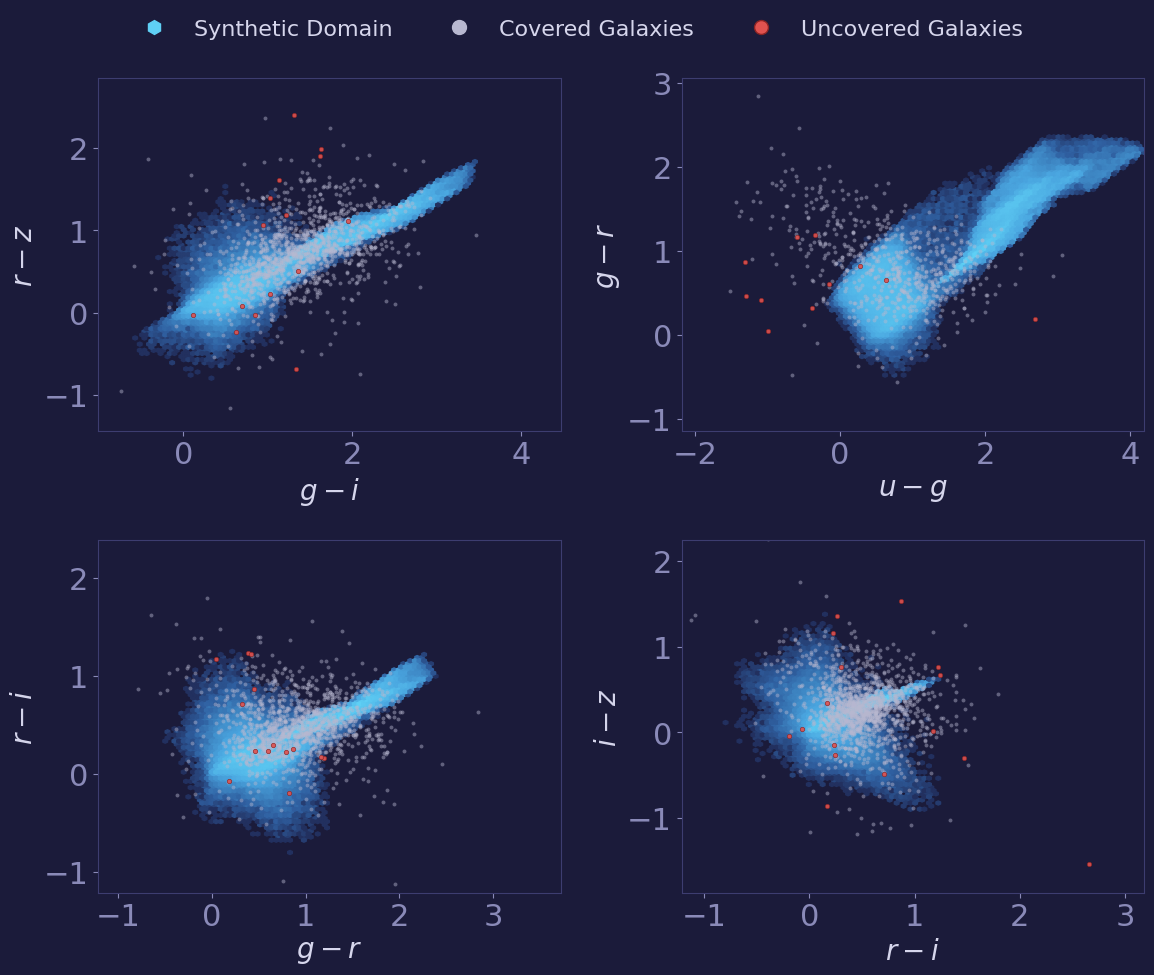

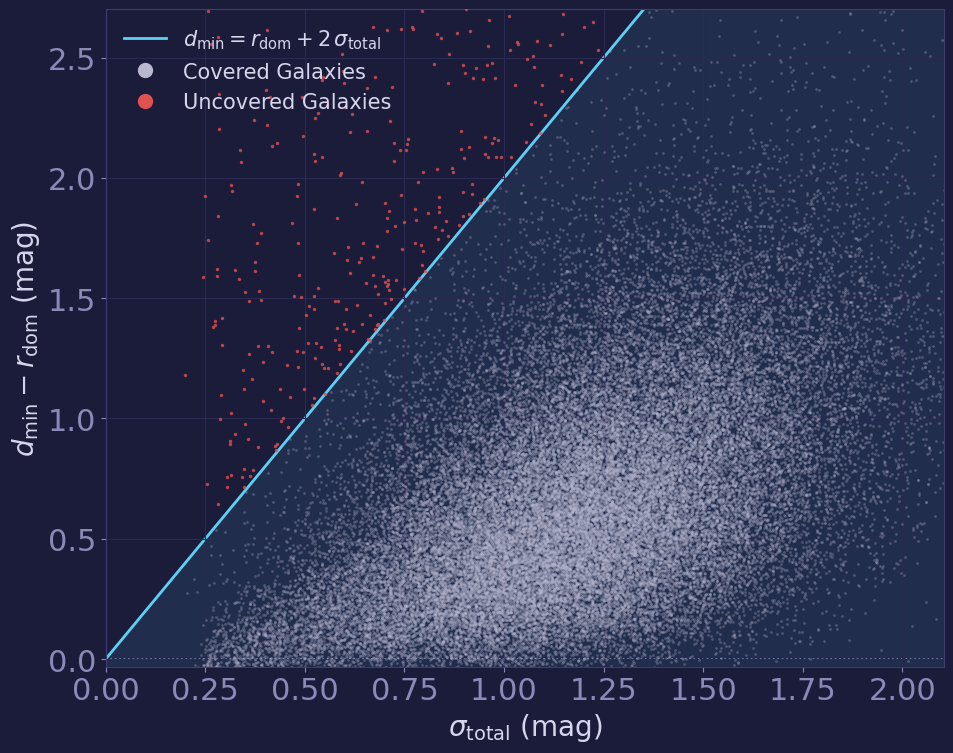

In [9]:
# =============================================================================
# GRÁFICOS DA COBERTURA GEOMÉTRICA (estilo do pôster)
#
# Rode depois de cobertura_geometrica.py: usa cores_modelos, cores_obs,
# nomes_cores, BANDA_REF, K_RUIDO e as colunas covered, d_min, r_dom e
# sigma_total do splus.
#
# Figura 1: diagramas cor-cor com o domínio sintético e as galáxias.
# Figura 2: o critério do teste, d_min - r_dom contra sigma_total.
# =============================================================================

from matplotlib.colors import LinearSegmentedColormap


# -----------------------------------------------------------------------------
# Paleta do pôster
# -----------------------------------------------------------------------------
POSTER = {
    "bg": "#12122b",       # fundo do pôster
    "panel": "#1b1b3a",    # caixas das figuras
    "grid": "#2a2a52",     # grade de fundo
    "edge": "#3d3d70",     # bordas
    "text": "#d6d6ec",     # texto
    "muted": "#8a8ab8",    # legendas "Figure N"
    "cyan": "#5fd0f5",     # títulos
    "red": "#e0524f",      # bloco vermelho do tetris
    "red_edge": "#8c2424",
    "covered": "#b8b8d0",  # galáxias cobertas
}
domain_cmap = LinearSegmentedColormap.from_list(
    "poster_blue", ["#22305f", "#2f5fa0", "#4aa6e0", POSTER["cyan"]])

style = {
    "figure.facecolor": POSTER["panel"],
    "axes.facecolor": POSTER["panel"],
    "axes.edgecolor": POSTER["edge"],
    "axes.labelcolor": POSTER["text"],
    "axes.labelsize": 20,
    "xtick.color": POSTER["muted"],
    "ytick.color": POSTER["muted"],
    "text.color": POSTER["text"],
    "font.family": "sans-serif",
    "legend.frameon": False,
}

plt.rcParams.update({"font.size": 22})


# -----------------------------------------------------------------------------
# Cores dos gráficos a partir das cores (banda - r) usadas no teste
#   Qualquer cor a - b pode ser escrita como (a - r) - (b - r).
# -----------------------------------------------------------------------------
def cor_menos_ref(cores, banda):
    """Coluna (banda - r) de um array de cores. Para a própria r, a cor é zero."""
    if banda == BANDA_REF:
        return np.zeros(len(cores))
    coluna = nomes_cores.index(f"{banda} - {BANDA_REF}")
    return cores[:, coluna]


def cor(cores, banda_1, banda_2):
    """Cor banda_1 - banda_2."""
    return cor_menos_ref(cores, banda_1) - cor_menos_ref(cores, banda_2)


def mediu_todas(bandas):
    """True para as galáxias que detectaram todas as bandas da lista."""
    mediu = np.ones(len(splus), dtype=bool)
    for banda in bandas:
        mediu = mediu & detected[:, BANDS.index(banda)]
    return mediu


coberta = splus["covered"].to_numpy()


# =============================================================================
# FIGURA 1: diagramas cor-cor
#   O domínio (hexbin) junta os modelos de todos os redshifts, como o teste.
#   Cada galáxia foi testada nas 11 cores; aqui só aparecem 2 delas.
# =============================================================================
paineis = [("g", "i", "r", "z"), ("u", "g", "g", "r"), ("g", "r", "r", "i"), ("r", "i", "i", "z")]
mostrar = np.random.default_rng(SEED).random(len(splus)) < 1500 / len(splus)

with plt.rc_context(style):
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    for ax, (a, b, c, d) in zip(axes.flat, paineis):
        # Domínio sintético neste plano
        x_modelos = cor(cores_modelos, a, b)
        y_modelos = cor(cores_modelos, c, d)

        # Galáxias sorteadas que mediram as 4 bandas do painel
        selecionadas = mostrar & mediu_todas([a, b, c, d])
        x_galaxias = cor(cores_obs, a, b)[selecionadas]
        y_galaxias = cor(cores_obs, c, d)[selecionadas]
        coberta_sel = coberta[selecionadas]

        # Limites a partir das galáxias, com espaço extra para a legenda
        xlim = np.percentile(x_galaxias, [0.5, 99.5]) + [-0.8, 1.7]
        ylim = np.percentile(y_galaxias, [0.5, 99.5]) + [-0.8, 0.95]

        ax.hexbin(x_modelos, y_modelos, extent=(*xlim, *ylim), bins="log", mincnt=1,
                  cmap=domain_cmap, zorder=1)
        ax.scatter(x_galaxias[coberta_sel], y_galaxias[coberta_sel],
                   s=8, c=POSTER["covered"], alpha=0.45, lw=0, zorder=2)
        ax.scatter(x_galaxias[~coberta_sel], y_galaxias[~coberta_sel],
                   s=10, c=POSTER["red"], alpha=0.9, edgecolors=POSTER["red_edge"], lw=0.5, zorder=3)

        ax.set(xlim=xlim, ylim=ylim, xlabel=f"${a} - {b}$", ylabel=f"${c} - {d}$")

    handles = [
        plt.Line2D([], [], ls="", marker="h", ms=10, color=POSTER["cyan"], label="Synthetic Domain"),
        plt.Line2D([], [], ls="", marker="o", ms=10, color=POSTER["covered"], label="Covered Galaxies"),
        plt.Line2D([], [], ls="", marker="o", ms=10, color=POSTER["red"], mec=POSTER["red_edge"],
                   label="Uncovered Galaxies"),
    ]
    fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=16, labelcolor=POSTER["text"])
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig("color_color.png", dpi=300, facecolor=fig.get_facecolor())
    plt.show()


# =============================================================================
# FIGURA 2: o critério do teste
#   Cada galáxia vira um ponto (sigma_total, d_min - r_dom).
#   Coberta  <=>  d_min - r_dom <= K * sigma_total  <=>  abaixo da reta.
#   Abaixo de zero: a galáxia está dentro de uma bola de raio r_dom.
# =============================================================================
sigma_total = splus["sigma_total"].to_numpy()
alem_do_dominio = (splus["d_min"] - splus["r_dom"]).to_numpy()

x_max = np.percentile(sigma_total, 99.5)
y_min = np.percentile(alem_do_dominio, 0.5)
y_max = np.percentile(alem_do_dominio, 99.5)

reta_x = np.array([0.0, x_max])
reta_y = K_RUIDO * reta_x

with plt.rc_context(style):
    fig, ax = plt.subplots(figsize=(10, 8))

    # Região coberta e fronteira do critério
    ax.fill_between(reta_x, y_min, reta_y, color=POSTER["cyan"], alpha=0.10, lw=0, zorder=0)
    ax.plot(reta_x, reta_y, color=POSTER["cyan"], lw=2, zorder=1)
    ax.axhline(0, color=POSTER["muted"], ls=":", lw=1.2, zorder=1)

    # Todas as galáxias
    ax.scatter(sigma_total[coberta], alem_do_dominio[coberta],
               s=4, c=POSTER["covered"], alpha=0.3, lw=0, zorder=2)
    ax.scatter(sigma_total[~coberta], alem_do_dominio[~coberta],
               s=6, c=POSTER["red"], alpha=0.8, lw=0, zorder=3)

    ax.set(xlim=(0, x_max), ylim=(y_min, y_max),
           xlabel=r"$\sigma_{\rm total}$ (mag)", ylabel=r"$d_{\rm min} - r_{\rm dom}$ (mag)")
    ax.grid(True, color=POSTER["grid"], lw=0.8, zorder=0)

    handles = [
        plt.Line2D([], [], color=POSTER["cyan"], lw=2,
                   label=rf"$d_{{\rm min}} = r_{{\rm dom}} + {K_RUIDO:g}\,\sigma_{{\rm total}}$"),
        plt.Line2D([], [], ls="", marker="o", ms=10, color=POSTER["covered"], label="Covered Galaxies"),
        plt.Line2D([], [], ls="", marker="o", ms=10, color=POSTER["red"], label="Uncovered Galaxies"),
    ]
    ax.legend(handles=handles, loc="best", fontsize=15, labelcolor=POSTER["text"])
    fig.tight_layout()
    fig.savefig("coverage_criterion.png", dpi=300, facecolor=fig.get_facecolor())
    plt.show()

['uJAVA', 'F0378', 'F0395', 'F0410', 'F0430', 'gSDSS', 'F0515', 'rSDSS', 'F0660', 'iSDSS', 'F0861', 'zSDSS']


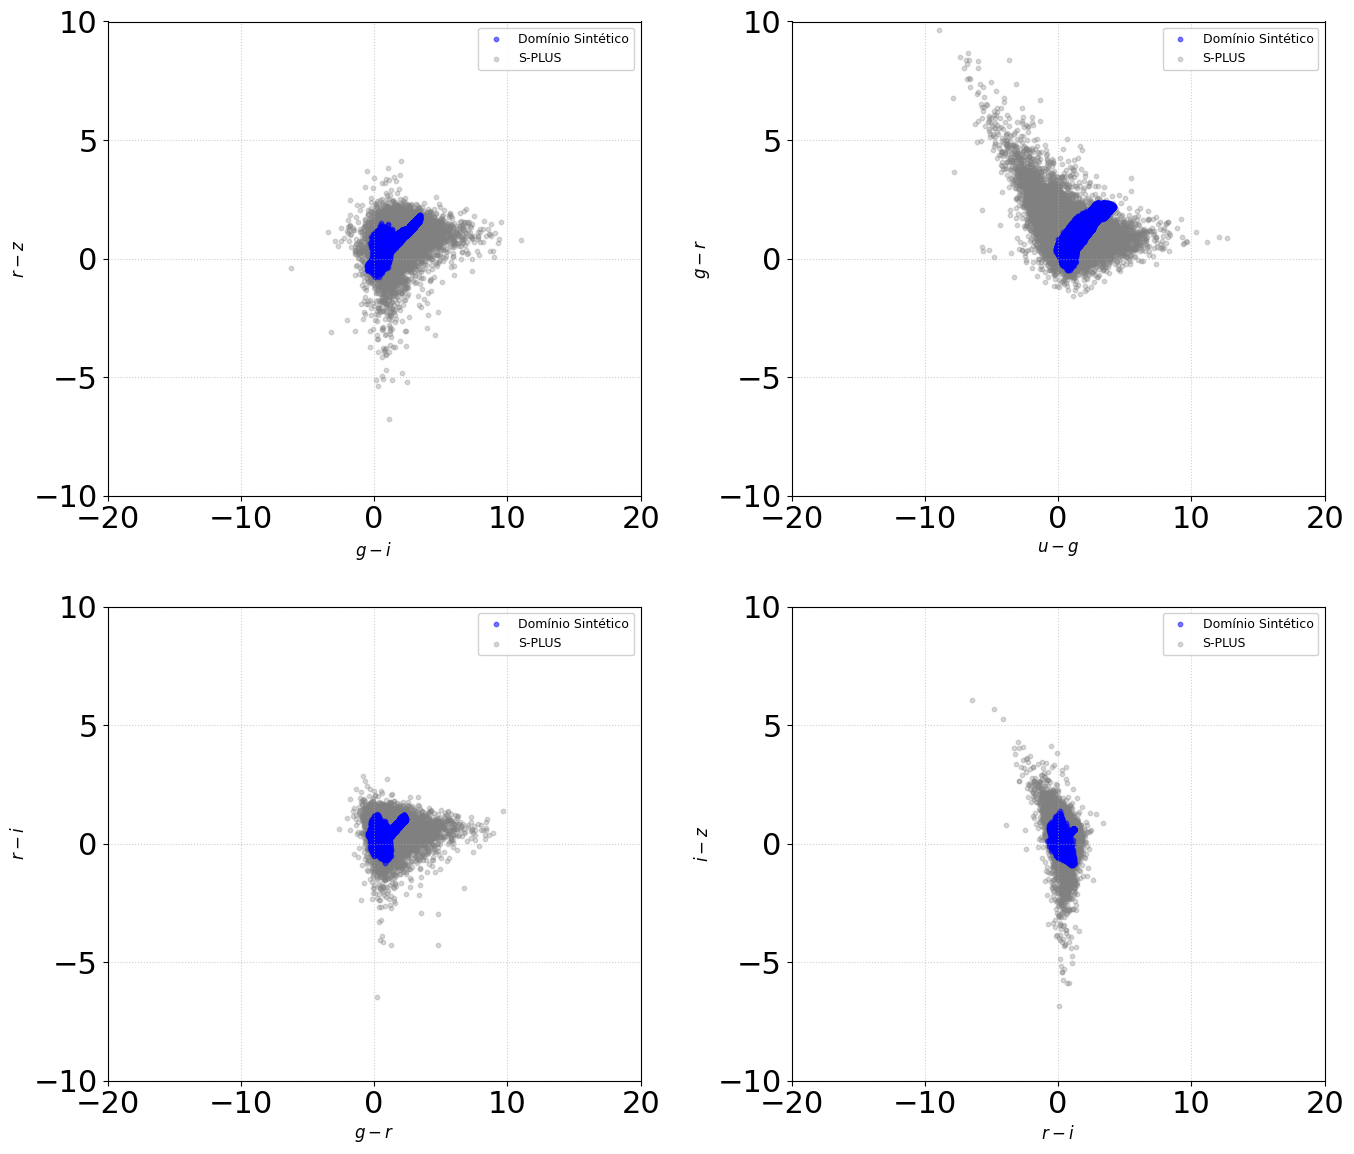

In [8]:
from scipy.spatial import ConvexHull
from matplotlib.lines import Line2D

plt.rcParams["text.usetex"] = False

model_grid = np.loadtxt("training_set.csv", delimiter=",", skiprows=1)
filt_splus_list = [filter.split("/")[1].split(".")[0] for filter in np.loadtxt("splus-filters/splus_filters.txt", dtype="str")]

print(filt_splus_list)

plot_configs = [
    {'x': ('gSDSS', 'iSDSS'), 'y': ('rSDSS', 'zSDSS'), 'xlab': '$g - i$', 'ylab': '$r - z$'},
    {'x': ('uJAVA', 'gSDSS'),  'y': ('gSDSS', 'rSDSS'), 'xlab': '$u - g$', 'ylab': '$g - r$'},
    {'x': ('gSDSS', 'rSDSS'), 'y': ('rSDSS', 'iSDSS'), 'xlab': '$g - r$', 'ylab': '$r - i$'},
    {'x': ('rSDSS', 'iSDSS'), 'y': ('iSDSS', 'zSDSS'), 'xlab': '$r - i$', 'ylab': '$i - z$'}
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

cmap = plt.get_cmap('jet')

# Loop sobre cada subplot e sua configuração de cor
for ax_idx, (ax, config) in enumerate(zip(axes, plot_configs)):
    
    b1_x, b2_x = config['x']
    b1_y, b2_y = config['y']
    
    all_x, all_y = [], []

    ax.scatter(model_grid[:, filt_splus_list.index(b1_x) + 12] - model_grid[:, filt_splus_list.index(b2_x) + 12],
               model_grid[:, filt_splus_list.index(b1_y) + 12] - model_grid[:, filt_splus_list.index(b2_y) + 12],
               c='blue', s=10, alpha=0.5, label='Domínio Sintético', zorder=1)

    splus_data_x = splus[b1_x[0] + '_auto'] - splus[b2_x[0] + '_auto']
    splus_data_y = splus[b1_y[0] + '_auto'] - splus[b2_y[0] + '_auto']

    ax.scatter(splus_data_x, splus_data_y, color='gray', alpha=0.3, s=10, zorder=0, label="S-PLUS") # Dados S-PLUS
    
    # Estilização de cada subplot
    ax.set_xlabel(config['xlab'], fontsize=12)
    ax.set_ylabel(config['ylab'], fontsize=12)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_xlim([-20, 20])
    ax.set_ylim([-10, 10])

    ax.legend(loc='best', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.show()